Project title: Random Forest(Minor project 4)

Name: Udeep Karmakar

Dataset name: healthcare-dataset-stroke-data.csv

Dataset link: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

In [5]:
!pip install -q kagglehub reportlab
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Shape:", df.shape)
df.head()


Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (2).csv
Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Missing values:
 bmi    201
dtype: int64
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


/tmp/ipykernel_495/1130531986.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="stroke", data=df, palette="Set2")


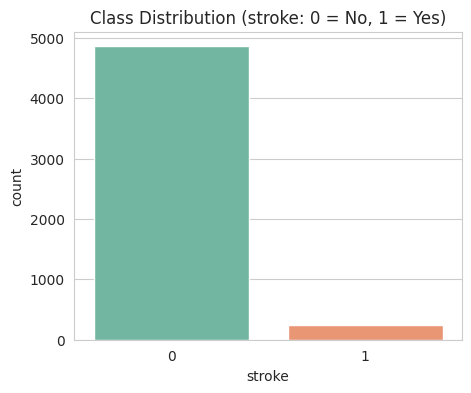

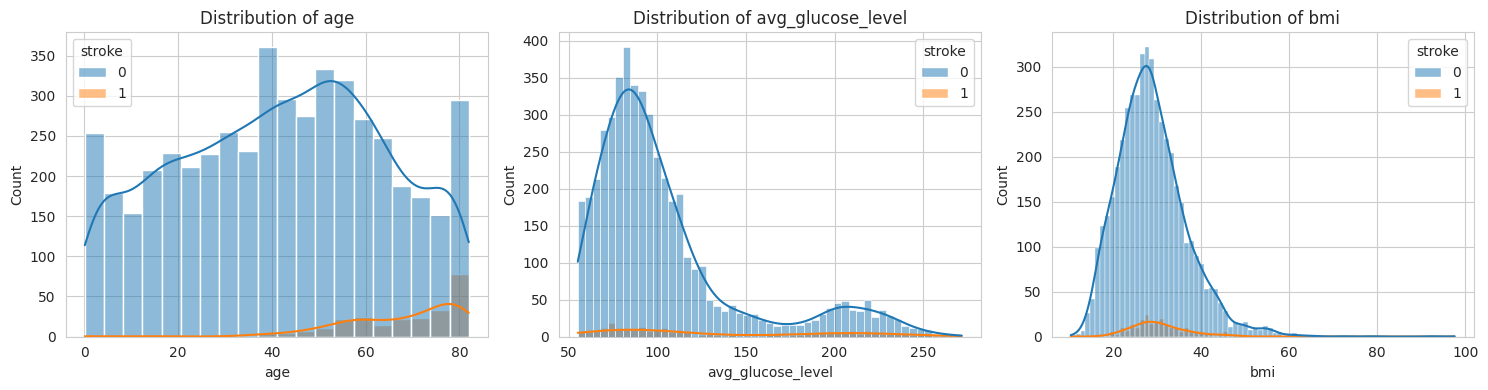

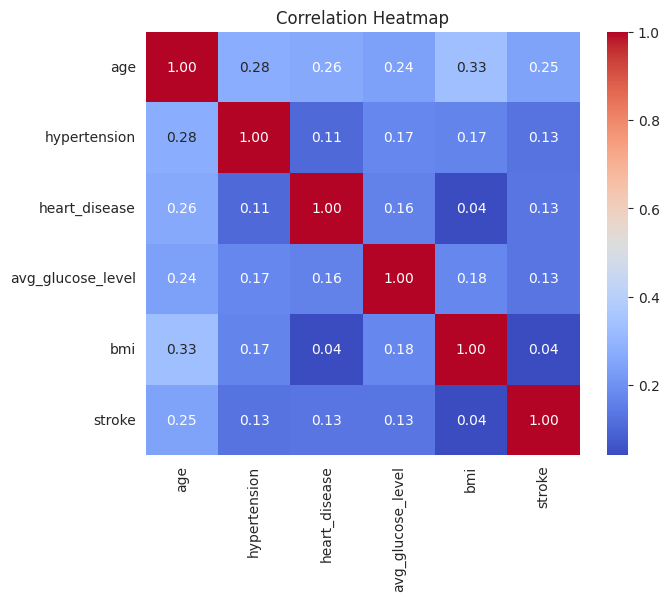

In [6]:
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

# 1) Class imbalance
class_pct = df["stroke"].value_counts(normalize=True) * 100
print(class_pct.round(2))
plt.figure(figsize=(5, 4))
sns.countplot(x="stroke", data=df, palette="Set2")
plt.title("Class Distribution (stroke: 0 = No, 1 = Yes)")
plt.savefig("figures/01_class_balance.png", dpi=300, bbox_inches="tight"); plt.show()

# 2) Feature distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.histplot(data=df, x=col, hue="stroke", kde=True, ax=ax, common_norm=False)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig("figures/02_distributions.png", dpi=300, bbox_inches="tight"); plt.show()

# 3) Correlation heatmap (numeric features + target)
num_cols = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]
corr = df[num_cols].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("figures/03_correlation_heatmap.png", dpi=300, bbox_inches="tight"); plt.show()
top_corr = corr["stroke"].drop("stroke").abs().idxmax()
top_corr_val = corr.loc[top_corr, "stroke"]

In [7]:
# Handle nulls: 'bmi' is skewed, so fill with the median
n_missing = int(df["bmi"].isnull().sum())
df["bmi"] = df["bmi"].fillna(df["bmi"].median())

# Drop ID column (no predictive value)
df = df.drop(columns="id")

# One-Hot Encoding for categorical features
X = pd.get_dummies(df.drop(columns="stroke"), drop_first=True)
y = df["stroke"]

# 80:20 split; stratify keeps the ~5% stroke ratio equal in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

# NOTE: No StandardScaler -> Random Forest splits on thresholds, not distances,
# so feature scaling does not change its results.

(4088, 16) (1022, 16)


In [8]:
# Grid search to JUSTIFY n_estimators and max_depth (scored on F1 because of imbalance)
param_grid = {"n_estimators": [100, 200, 300], "max_depth": [3, 5, 8, 12, None]}
grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_grid, cv=3, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

rf = grid.best_estimator_
best = grid.best_params_
print("Best params:", best, "| CV F1:", round(grid.best_score_, 4))

Best params: {'max_depth': 5, 'n_estimators': 100} | CV F1: 0.2252


{'Accuracy': 0.7172, 'Precision': 0.1254, 'Recall': 0.8, 'F1-Score': 0.2168, 'ROC-AUC': np.float64(0.8419)}
              precision    recall  f1-score   support

   No Stroke       0.99      0.71      0.83       972
      Stroke       0.13      0.80      0.22        50

    accuracy                           0.72      1022
   macro avg       0.56      0.76      0.52      1022
weighted avg       0.94      0.72      0.80      1022



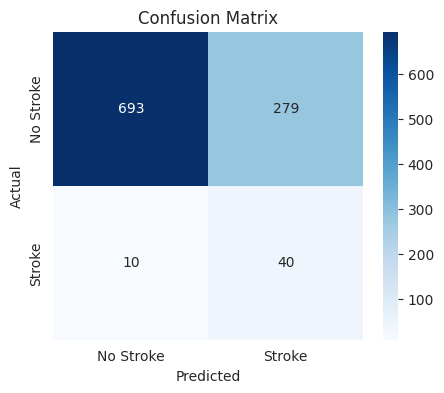

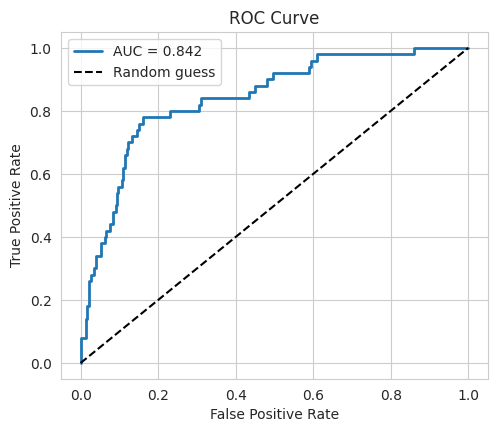

/tmp/ipykernel_495/1115913891.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp.values, y=imp.index, palette="viridis")


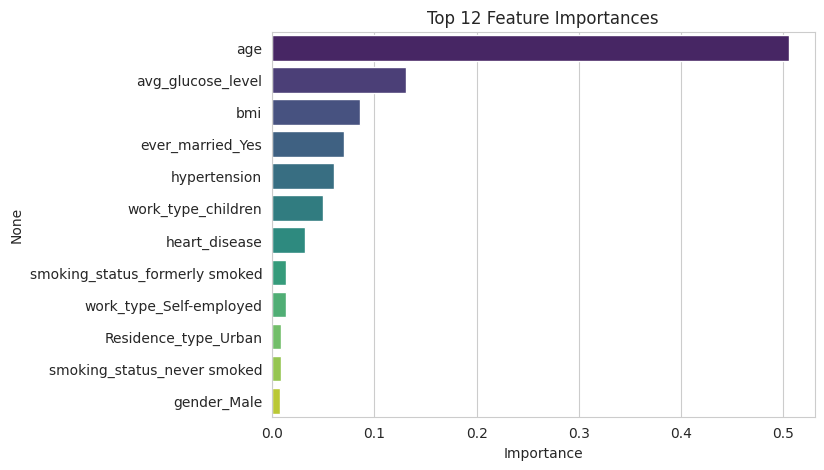

In [9]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}
print({k: round(v, 4) for k, v in metrics.items()})
print(classification_report(y_test, y_pred, target_names=["No Stroke", "Stroke"]))

# 1) Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Stroke", "Stroke"], yticklabels=["No Stroke", "Stroke"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix")
plt.savefig("figures/04_confusion_matrix.png", dpi=300, bbox_inches="tight"); plt.show()

# 2) ROC curve + AUC
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"AUC = {metrics['ROC-AUC']:.3f}", lw=2)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.savefig("figures/05_roc_curve.png", dpi=300, bbox_inches="tight"); plt.show()

# 3) Feature importance (top 12)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(7, 5))
sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Top 12 Feature Importances"); plt.xlabel("Importance")
plt.savefig("figures/06_feature_importance.png", dpi=300, bbox_inches="tight"); plt.show()